In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [5]:
df = pd.read_csv('ecommerce_clean_data.csv')

In [6]:
df.head()

,OrderID,OrderDate,CustomerID,PaymentMethod,OrderStatus,CustomerName,Gender,Age,City,Region,...,Profit,ProductName,Category,CostPrice,SellingPrice,Year,Month,Monthname,Year Name,profitmarginPct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [7]:
df.shape

(12558, 27)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          12558 non-null  str    
 1   OrderDate        12558 non-null  str    
 2   CustomerID       12558 non-null  str    
 3   PaymentMethod    12558 non-null  str    
 4   OrderStatus      12558 non-null  str    
 5   CustomerName     12558 non-null  str    
 6   Gender           12558 non-null  str    
 7   Age              12558 non-null  int64  
 8   City             12558 non-null  str    
 9   Region           12558 non-null  str    
 10  SignupDate       12558 non-null  str    
 11  OrderDetailID    12558 non-null  str    
 12  ProductID        12558 non-null  str    
 13  Quantity         12558 non-null  int64  
 14  UnitPrice        12558 non-null  float64
 15  DiscountPct      12558 non-null  float64
 16  SalesAmount      12558 non-null  float64
 17  Profit           12558 

In [9]:
df.describe()

,Age,Quantity,UnitPrice,DiscountPct,SalesAmount,Profit,CostPrice,SellingPrice,Year,Month,profitmarginPct
count,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000
mean,39.065377,2.501752,6272.299570,10.742156,14010.138708,4804.382457,3680.883023,6272.299570,2024.835165,6.002150,31.293145
std,12.303175,1.119501,3461.536155,7.112802,10628.052040,4894.725391,1846.766235,3461.536155,0.762190,3.287781,13.355564
min,18.000000,1.000000,319.000000,0.000000,239.250000,-2048.000000,232.000000,319.000000,2024.000000,1.000000,-10.940224
25%,28.000000,2.000000,3416.000000,5.000000,5949.000000,1342.400000,2400.000000,3416.000000,2024.000000,3.000000,21.079173
50%,40.000000,2.000000,6288.000000,10.000000,11210.400000,3215.600000,3640.000000,6288.000000,2025.000000,6.000000,32.433378
75%,50.000000,4.000000,8847.000000,15.000000,20044.800000,6608.400000,5353.000000,8847.000000,2025.000000,9.000000,42.278551
max,60.000000,4.000000,14270.000000,25.000000,57080.000000,30860.000000,6882.000000,14270.000000,2026.000000,12.000000,54.342273


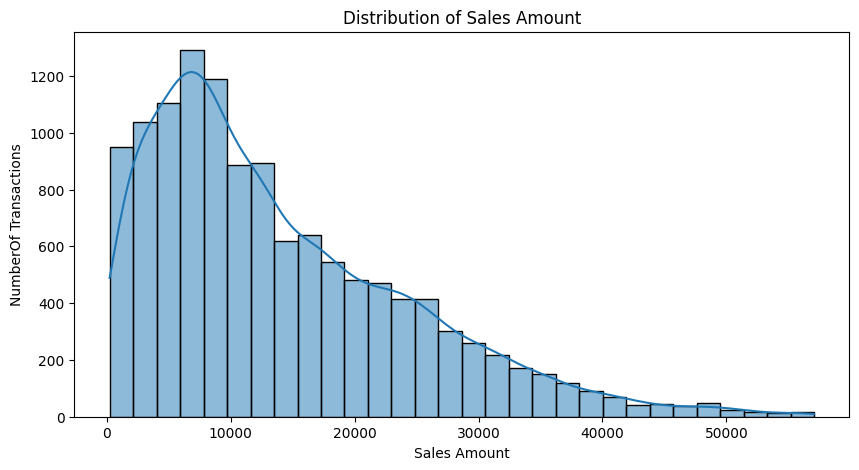

In [10]:
plt.figure(figsize = (10,5))
sns.histplot(
    df['SalesAmount'],
    bins = 30,
    kde = True
)
plt.title('Distribution of Sales Amount')
plt.xlabel('Sales Amount')
plt.ylabel('NumberOf Transactions')
plt.show()

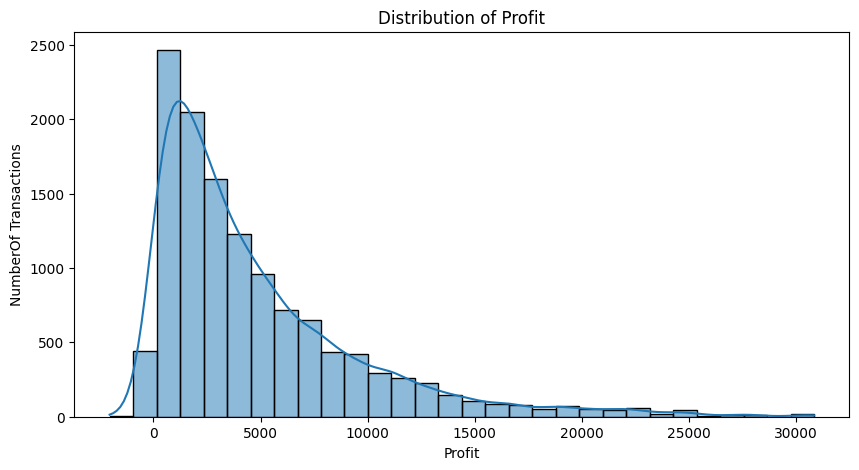

In [11]:
plt.figure(figsize = (10,5))
sns.histplot(
    df['Profit'],
    bins = 30,
    kde = True
)
plt.title('Distribution of Profit')
plt.xlabel('Profit')
plt.ylabel('NumberOf Transactions')
plt.show()

In [12]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerID', 'PaymentMethod', 'OrderStatus',
       'CustomerName', 'Gender', 'Age', 'City', 'Region', 'SignupDate',
       'OrderDetailID', 'ProductID', 'Quantity', 'UnitPrice', 'DiscountPct',
       'SalesAmount', 'Profit', 'ProductName', 'Category', 'CostPrice',
       'SellingPrice', 'Year', 'Month', 'Monthname', 'Year Name',
       'profitmarginPct'],
      dtype='str')

In [13]:
#Monthly revenue trend

In [14]:
Monthly_Sales = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("Year Name")["SalesAmount"]
    .sum()
    .reset_index()
)

In [15]:
Monthly_Sales

,Year Name,SalesAmount
0,2024-01,4690868.90
1,2024-02,4089338.70
2,2024-03,5296276.35
3,2024-04,4677015.85
4,2024-05,5020831.80
5,2024-06,5343347.60
6,2024-07,6165635.20
7,2024-08,5359728.15
8,2024-09,5302620.35
9,2024-10,4759925.10


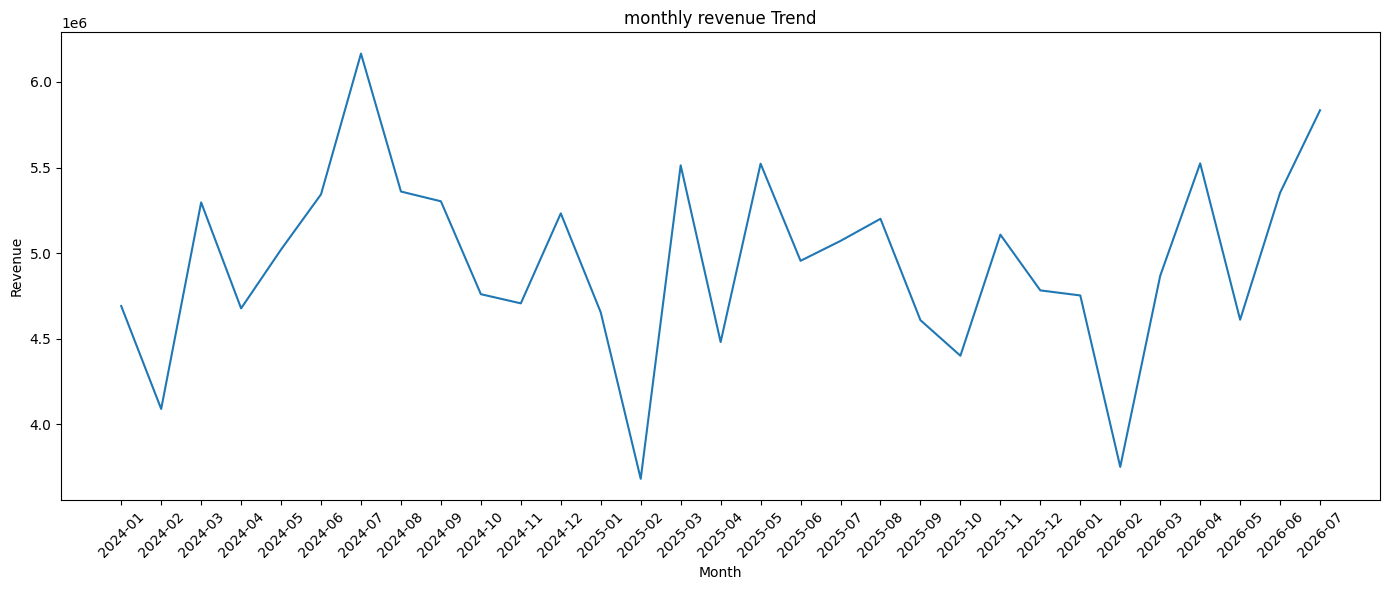

In [16]:
plt.figure(figsize=(14,6))
plt.plot(
    Monthly_Sales["Year Name"],
    Monthly_Sales["SalesAmount"]
)

plt.title("monthly revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
Monthly_Profit = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("Year Name")["Profit"]
    .sum()
    .reset_index()
)

In [18]:
Monthly_Profit

,Year Name,Profit
0,2024-01,1656481.90
1,2024-02,1447540.70
2,2024-03,1835204.35
3,2024-04,1561253.85
4,2024-05,1731669.80
5,2024-06,1860319.60
6,2024-07,2044670.20
7,2024-08,1813577.15
8,2024-09,1809531.35
9,2024-10,1623537.10


In [19]:
category_sales = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("Category")["SalesAmount"]
    .sum()
    .sort_values(ascending = False)
)

In [20]:
category_sales

Category
Home           41719144.50
Electronics    39483785.90
Fashion        30509991.50
Beauty         24937008.05
Books          16662009.60
Name: SalesAmount, dtype: float64

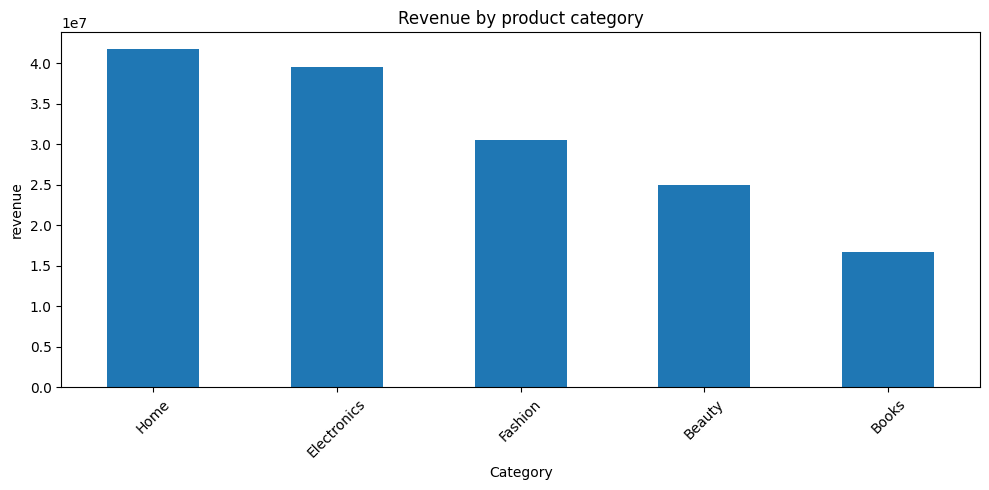

In [21]:
plt.figure(figsize=(10,5))

category_sales.plot(kind = "bar")

plt.title("Revenue by product category")
plt.xlabel("Category")
plt.ylabel("revenue")

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [22]:
category_Profit = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending = False))

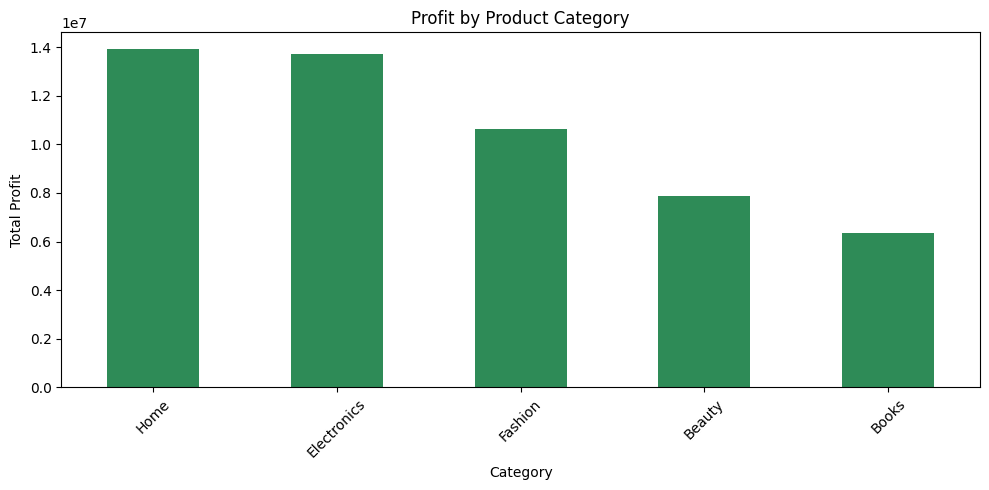

In [23]:

plt.figure(figsize=(10, 5))

category_Profit.plot(kind="bar", color="seagreen")

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [2]:
# Region erformance

In [24]:

region_sales = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("Region")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

region_sales


Region
South    48017312.80
West     45495911.75
North    43227025.55
East     16571689.45
Name: SalesAmount, dtype: float64

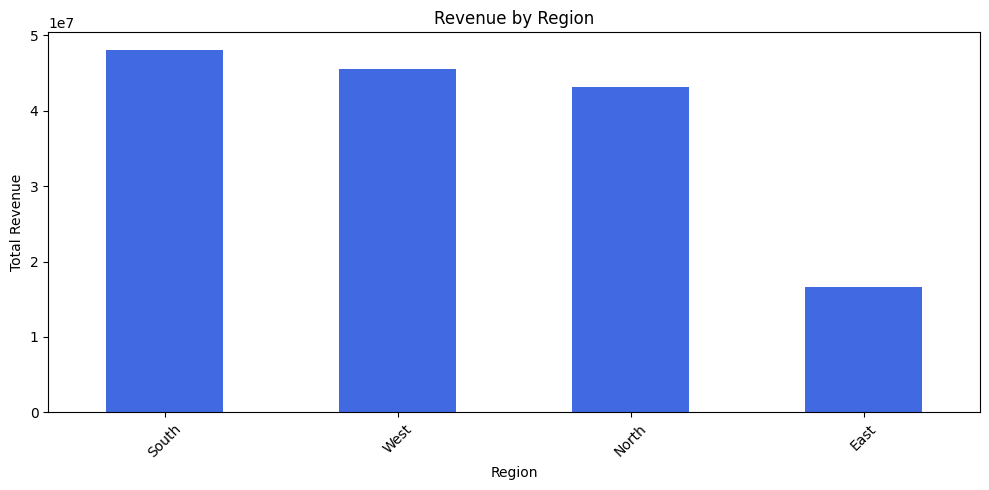

In [26]:

plt.figure(figsize=(10, 5))

region_sales.plot(kind="bar", color="royalblue")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [81]:
# Customer kaunsa payment method zyada use kar rhe hain

In [82]:
payment_analysis = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("PaymentMethod")["OrderID"]
    .nunique()
    .sort_values(ascending = False))

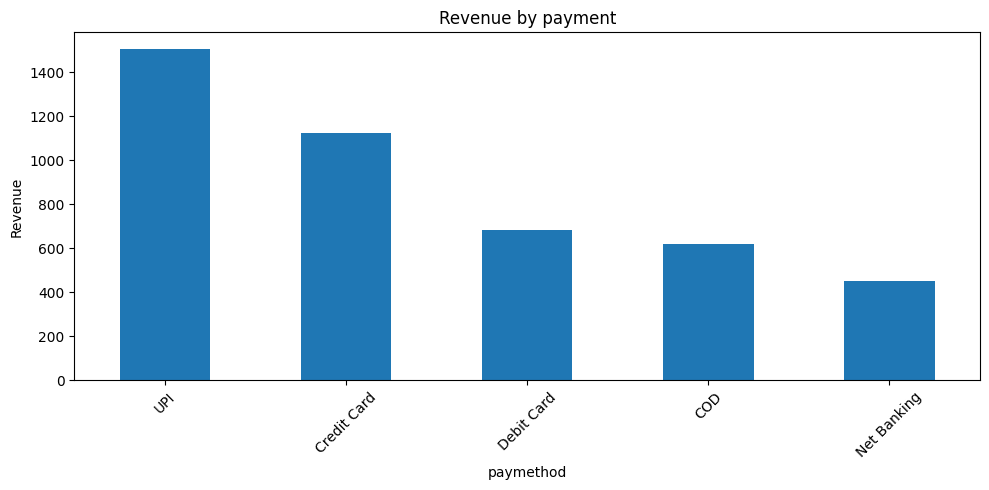

In [83]:
plt.figure(figsize=(10,5))

payment_analysis.plot(kind = "bar")

plt.title("Revenue by payment")
plt.xlabel("paymethod")
plt.ylabel("Revenue")

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [84]:
# what is the profit changes after changing discount

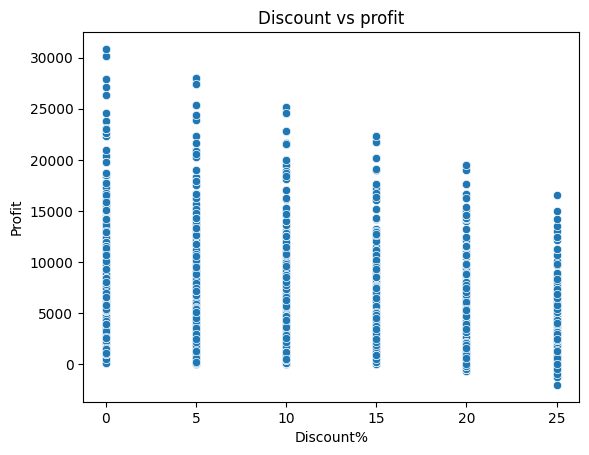

In [85]:
plt.Figure(figsize=(10,6))

sns.scatterplot(
    data = df[df["OrderStatus"] == "Delivered"],
    x = "DiscountPct",
    y = "Profit"

)

plt.title("Discount vs profit")
plt.xlabel("Discount%")
plt.ylabel("Profit")
plt.show()

In [86]:
Numeric_cols = ["Age",
"Quantity",
"UnitPrice",
"DiscountPct",
"SalesAmount",
"Profit"]

In [87]:
correlation = df[Numeric_cols].corr()

In [88]:
correlation

,Age,Quantity,UnitPrice,DiscountPct,SalesAmount,Profit
Age,1.000000,0.005574,-0.001661,-0.000709,0.000313,0.003488
Quantity,0.005574,1.000000,-0.000415,0.002037,0.588638,0.438354
UnitPrice,-0.001661,-0.000415,1.000000,-0.003870,0.727013,0.699047
DiscountPct,-0.000709,0.002037,-0.003870,1.000000,-0.111380,-0.235076
SalesAmount,0.000313,0.588638,0.727013,-0.111380,1.000000,0.907850
Profit,0.003488,0.438354,0.699047,-0.235076,0.907850,1.000000


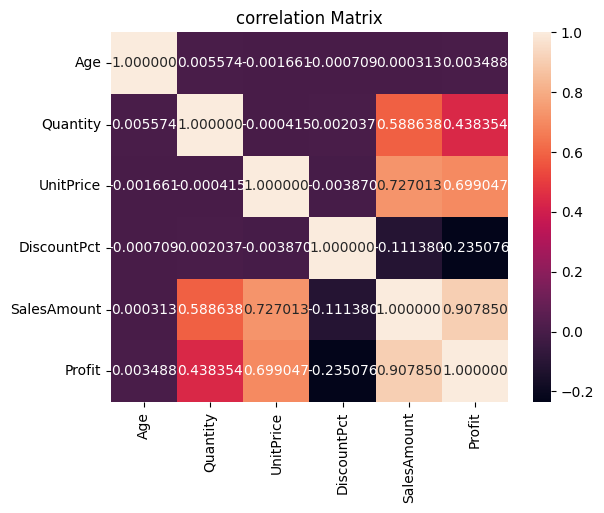

In [89]:
plt.Figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot = True,
    fmt = "2f"
)
plt.title("correlation Matrix")
plt.show()

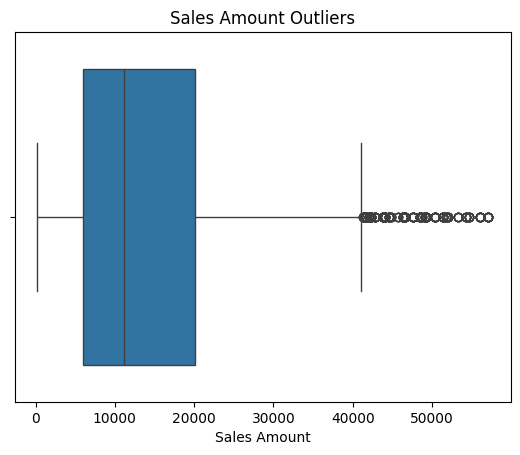

In [90]:
plt.Figure(figsize=(10,7))

sns.boxplot(
    x =df["SalesAmount"]
)
plt.title("Sales Amount Outliers")
plt.xlabel("Sales Amount")
plt.show()

In [91]:
Top_product = (
    df[df["OrderStatus"] == "Delivered"]
    .groupby("ProductName")["SalesAmount"]
    .sum()
    .sort_values(ascending = False)
    .head(10))

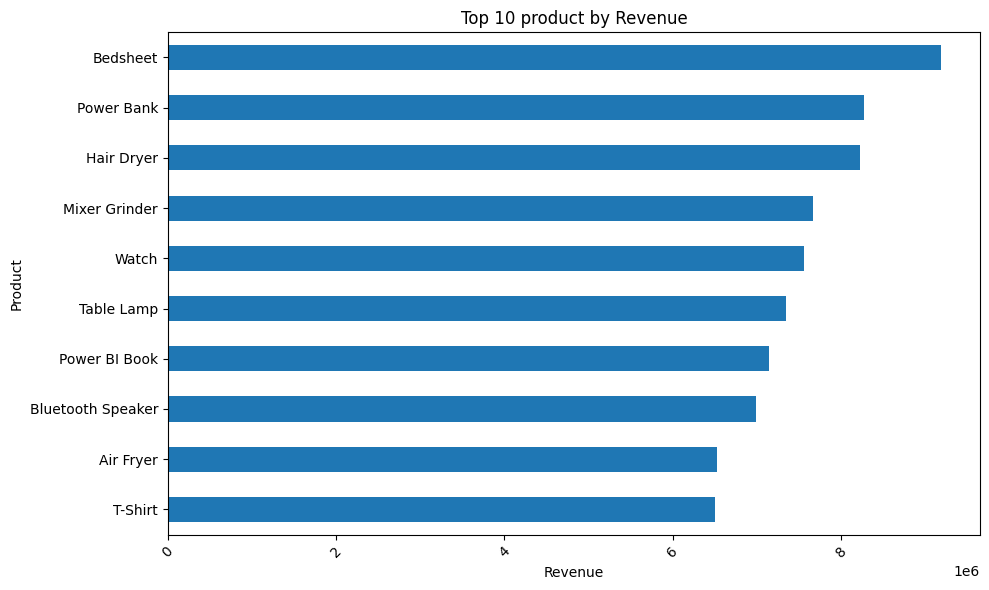

In [92]:
plt.figure(figsize=(10,6))

Top_product.sort_values().plot(kind = "barh")

plt.title("Top 10 product by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [94]:
return_analysis = (
    return
    .groupby("ReturnReason")
    .size()
    .sort_values(ascending = False))

SyntaxError: invalid syntax (2447907776.py, line 2)

In [95]:
eda_summary = pd.DataFrame({
    "Analysis": [
        "Monthly Revenue",
        "Category Perfoemance",
        "Region Performance",
        "Discount vs Profit",
        "Top Product",
        "Return Reason"
    ],

    "Business_Purpose": [
    "Identify sales trend",
    "Find high-performing categories",
    "Compare regional performance",
    "Understand discount impact",
    "Identify important products",
    "Identify return problems"
    ]
})

In [96]:
eda_summary

,Analysis,Business_Purpose
0,Monthly Revenue,Identify sales trend
1,Category Perfoemance,Find high-performing categories
2,Region Performance,Compare regional performance
3,Discount vs Profit,Understand discount impact
4,Top Product,Identify important products
5,Return Reason,Identify return problems
